# SOLSTICE state model on the SOLPS-NN test set: the paper's figures and tables

Evaluates a trained SOLSTICE GNN (`solstice-train`, `best.pt` in `$SOLSTICE_RUN`; a glob over the
seeds of an ensemble averages their predictions, a deep ensemble) on the held-out test split of the SOLPS-NN release and reproduces, with our predictions, the figures and tables of
*Dasbach et al., arXiv:2604.19223*: Figure 1 (regimes), Figure 2 (2D fields), Figure 3 (outer-target
Te profiles), Table 2 (Te errors: 2D, outer target per regime, OMP separatrix), Table 3 (outer-target
separatrix Te, ne, nD, nN, pe) and Table 4 / Figure 5 (peak outer-target heat flux). The paper's
numbers are hard-coded next to ours. Beyond the paper: the radiated power and heat-flux fields.

## Setup

In [1]:
import os, json, glob, time
from pathlib import Path
import numpy as np, xarray as xr, torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import PolyCollection
from solstice.training.evaluate import load_export, predict, evaluate, format_metrics
from solstice.training.data import engineer_inputs, select_cases, target_cells

# Paths: set SOLSTICE_RUN (dir with best.pt, or a glob / space-separated globs over the seed dirs
# of an ensemble) and SOLSTICE_DATA (dir with the two stores) in the environment, or edit here.
# Defaults: the 20-seed heads5_h1024 + Te fine-tune ensemble and the Perlmutter data directory.
REPO = Path.cwd() if (Path.cwd() / 'configs').exists() else Path.cwd().parent
RUNS = []
for pat in os.environ.get('SOLSTICE_RUN', 'runs/ensemble/heads5_h1024/seed*_ft_te').split():
    if not Path(pat).is_absolute():    # relative to the repo root, also under nbconvert (cwd = notebooks/)
        pat = str(REPO / pat)
    RUNS += sorted((Path(r) for r in glob.glob(pat)), key=lambda r: (len(r.name), r.name))
RUN = RUNS[0]                          # config / training curve of the first seed
DATA = Path(os.environ.get('SOLSTICE_DATA', '/pscratch/sd/d/diawa/nn'))
if not DATA.exists():
    DATA = REPO / 'dasbach_dataset' / 'stores'
assert RUNS and all((r / 'best.pt').exists() for r in RUNS), f'no best.pt in every run of {RUNS}'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'{len(RUNS)} run(s):', ', '.join(r.name for r in RUNS), '| in', RUN.parent, '| data:', DATA, '| device:', DEVICE)

REGIMES = ['sheath-limited', 'attached', 'detached', 'cold core']
RCOL = dict(zip(REGIMES, ['#2a78d6', '#eb6834', '#1baf7a', '#e34948']))
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'legend.frameon': False})

20 run(s): seed0_ft_te, seed1_ft_te, seed2_ft_te, seed3_ft_te, seed4_ft_te, seed5_ft_te, seed6_ft_te, seed7_ft_te, seed8_ft_te, seed9_ft_te, seed10_ft_te, seed11_ft_te, seed12_ft_te, seed13_ft_te, seed14_ft_te, seed15_ft_te, seed16_ft_te, seed17_ft_te, seed18_ft_te, seed19_ft_te | in /pscratch/sd/d/diawa/nn/solstice-exp/runs/ensemble/heads5_h1024 | data: /pscratch/sd/d/diawa/nn | device: cuda


## Data check: test cases never seen in training

The SOLPS-NN release ships its own `train` and `test` directories; the two stores are built
from them one to one. Checked here: no case id in common, every checkpoint records the train
store it was fitted on, and the test store is the one the paper's numbers refer to.

In [2]:
dt = xr.open_dataset(DATA / 'solstice_store_solpsnn_v1_test.nc'); dtr = xr.open_dataset(DATA / 'solstice_store_solpsnn_v1_train.nc')
tr_ids, te_ids = set(dtr.case.values), set(dt.case.values)
assert not (tr_ids & te_ids), 'train and test stores overlap'
gits = set()
for r in RUNS:
    pt = torch.load(r / 'best.pt', map_location='cpu', weights_only=False); gits.add(pt['code_git'])
    assert Path(pt['train_store']).name == 'solstice_store_solpsnn_v1_train.nc', f'{r.name} trained on {pt["train_store"]}'
    assert Path(pt['train_config']['data']['test_store']).name == 'solstice_store_solpsnn_v1_test.nc'
print(f'train {len(tr_ids)} / test {len(te_ids)} cases ({int(dt.qc_pass.values.sum())} qc_pass), no overlap; '
      f'{len(RUNS)} checkpoint(s) trained on solstice_store_solpsnn_v1_train.nc, code git {sorted(gits)}')
dtr.close()

train 5756 / test 1465 cases (1465 qc_pass), no overlap; 20 checkpoint(s) trained on solstice_store_solpsnn_v1_train.nc, code git ['ec57fd2', 'f09baf1']


## Model, predictions on the test split

With several runs the prediction `P` is the deep-ensemble mean of the normalized outputs, after
bringing every member to the first run's normalization (each run fits its own per-cell quantile
map on its own train split); this is what `scripts/nersc/ensemble_eval.py` computes, and every
table and figure below uses that mean. The
per-seed `Te` errors give the seed-to-seed spread, and the per-cell standard deviation of `Te`
across seeds (`te_std`) is the ensemble's uncertainty estimate, checked against the actual error
in the last section.

seed0_ft_te    te median rel. error: all cells 5.2%, outer target 10.8%  (116 s)


seed1_ft_te    te median rel. error: all cells 5.1%, outer target 10.5%  (219 s)


seed2_ft_te    te median rel. error: all cells 5.2%, outer target 10.6%  (320 s)


seed3_ft_te    te median rel. error: all cells 5.7%, outer target 11.3%  (419 s)


seed4_ft_te    te median rel. error: all cells 5.2%, outer target 10.8%  (521 s)


...

seed16_ft_te   te median rel. error: all cells 5.2%, outer target 10.4%  (1721 s)


seed17_ft_te   te median rel. error: all cells 5.2%, outer target 10.5%  (1820 s)


seed18_ft_te   te median rel. error: all cells 5.3%, outer target 10.8%  (1919 s)


seed19_ft_te   te median rel. error: all cells 5.1%, outer target 10.5%  (2019 s)



1465 test cases; 5,276,827 parameters per model; 20 model(s); outputs: ['te', 'ti', 'ne', 'na_D0', 'na_D1', 'na_N0', 'na_N1', 'na_N2', 'na_N3', 'na_N4', 'na_N5', 'na_N6', 'na_N7', 'ua_D0', 'ua_D1', 'ua_N0', 'ua_N1', 'ua_N2', 'ua_N3', 'ua_N4', 'ua_N5', 'ua_N6', 'ua_N7', 'q_pol', 'prad', 'q_target', 'gamma_target']
single seeds: te all cells 5.2 +- 0.2% (min 4.9, max 5.7), outer target 10.6 +- 0.3%


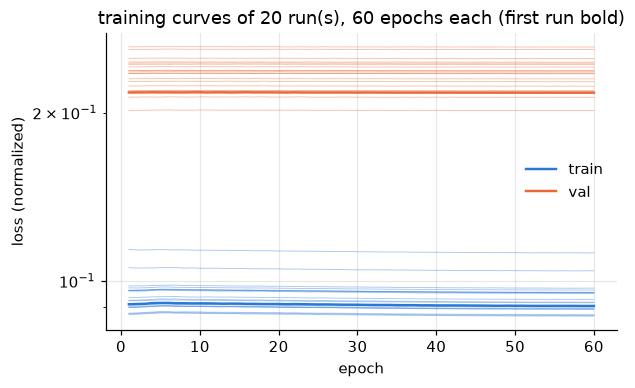

In [3]:
dt = xr.open_dataset(DATA / 'solstice_store_solpsnn_v1_test.nc')
idx = select_cases(dt)
regime = dt['regime'].values[idx]
t0 = time.time(); P = None; singles = []
for r in RUNS:
    model, in_norm, out_norm, graph = load_export(r / 'best.pt', dt, DEVICE)
    Xn = in_norm.transform(engineer_inputs(dt))[idx]   # this seed's own input normalization
    if P is None:
        Yt = out_norm.transform(dt)[idx]               # (case, cell, field) normalized truth
        norm0 = out_norm
        NAMES = out_norm.names
        J = {n: j for j, n in enumerate(NAMES)}
        def phys(arr, name):
            '''normalized (case, cell, field) -> physical units of one field, (case, cell)'''
            return norm0.inverse(arr[..., J[name]], J[name])
        n_par = sum(p.numel() for p in model.parameters())
        P = np.zeros_like(Yt); te_s1 = np.zeros(Yt.shape[:2]); te_s2 = np.zeros(Yt.shape[:2])
    Pr = predict(model, graph, Xn, DEVICE, batch=32)   # normalized predictions of this seed
    Yt_r = out_norm.transform(dt)[idx]                 # in this seed's own normalization
    m = evaluate(dt, idx, out_norm, Pr, Yt_r)['fields']['te']
    if out_norm is not norm0:                          # each run fits its own OutputNorm on its
        Pr = norm0.renormalize(Pr, out_norm)           # own train split: average in the first one's
    P += Pr; te_r = phys(Pr, 'te'); te_s1 += te_r; te_s2 += te_r ** 2
    singles.append((r.name, m['all_cells']['rel_median'], m['outer_target']['rel_median']))
    print(f"{r.name:14s} te median rel. error: all cells {100 * singles[-1][1]:.1f}%, outer target "
          f"{100 * singles[-1][2]:.1f}%  ({time.time() - t0:.0f} s)", flush=True)
    del model; torch.cuda.empty_cache() if DEVICE == 'cuda' else None
P /= len(RUNS)
te_mean = te_s1 / len(RUNS); te_std = np.sqrt(np.maximum(te_s2 / len(RUNS) - te_mean ** 2, 0))
print(f'\n{len(idx)} test cases; {n_par:,} parameters per model; {len(RUNS)} model(s); outputs: {NAMES}')
if len(RUNS) > 1:
    a, o = np.array([s[1] for s in singles]), np.array([s[2] for s in singles])
    print(f'single seeds: te all cells {100 * a.mean():.1f} +- {100 * a.std():.1f}% '
          f'(min {100 * a.min():.1f}, max {100 * a.max():.1f}), outer target {100 * o.mean():.1f} +- {100 * o.std():.1f}%')
fig, ax = plt.subplots(figsize=(6, 3.5))
for i, r in enumerate(RUNS):
    if not (r / 'log.jsonl').exists():
        continue
    hist = [json.loads(l) for l in open(r / 'log.jsonl')]
    kw = dict(lw=1.6, label=('train', 'val')) if i == 0 else dict(lw=0.6, alpha=0.4, label=(None, None))
    ax.plot([h['epoch'] for h in hist], [h['train_loss'] for h in hist], color='#2a78d6', lw=kw['lw'], alpha=kw.get('alpha', 1), label=kw['label'][0])
    ax.plot([h['epoch'] for h in hist], [h['val_loss'] for h in hist], color='#eb6834', lw=kw['lw'], alpha=kw.get('alpha', 1), label=kw['label'][1])
ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('loss (normalized)'); ax.legend()
ax.set_title(f'training curves of {len(RUNS)} run(s), {len(hist)} epochs each (first run bold)'); plt.show()

## Geometry helpers

The store's mesh is the unscaled JET baserun; each case is scaled by `mesh_scale = R / R_JET`.
Cell indices used by the paper: outer target `ix = 102`, OMP `ix = 64`, first SOL tube `iy = 25`.

In [4]:
IX_OMP, IY_SEP, IX_OT = int(dt.attrs['ix_omp']), int(dt.attrs['iy_sep']), int(dt.attrs['ix_ot'])
ix, iy = dt['cell_ix'].values, dt['cell_iy'].values
OMP_SEP = int(np.where((ix == IX_OMP) & (iy == IY_SEP))[0][0])
OUTER = target_cells(dt, 'outer_target')                       # ordered along iy
OT_SEP = int(OUTER[IY_SEP - 1])
VERTS0 = np.stack([dt['cell_corners_r'].values, dt['cell_corners_z'].values], axis=-1)
RC0, ZC0 = dt['cell_r'].values, dt['cell_z'].values

def plot_field(ax, vals, scale=1.0, log=True, vmin=None, vmax=None, cmap='viridis', zoom=None, title=''):
    vals = np.asarray(vals, float)
    ok = np.isfinite(vals) & ((vals > 0) if log else True)
    norm = (mcolors.LogNorm if log else mcolors.Normalize)(vmin=vmin or np.nanmin(vals[ok]), vmax=vmax or np.nanmax(vals[ok]))
    pc = PolyCollection(VERTS0 * scale, array=np.where(ok, vals, np.nan), norm=norm, cmap=cmap, edgecolor='none', rasterized=True)
    ax.add_collection(pc)
    lim = zoom or (VERTS0[..., 0].min(), VERTS0[..., 0].max(), VERTS0[..., 1].min(), VERTS0[..., 1].max())
    ax.set_xlim(lim[0] * scale, lim[1] * scale); ax.set_ylim(lim[2] * scale, lim[3] * scale)
    ax.set_aspect('equal'); ax.grid(False); ax.set_title(title, fontsize=10)
    return pc

def target_position(k):
    s = float(dt['mesh_scale'].values[idx[k]])
    r, z = RC0[OUTER] * s, ZC0[OUTER] * s
    return np.concatenate([[0], np.cumsum(np.hypot(np.diff(r), np.diff(z)))])

## Figure 1: regimes from predicted temperatures

Left: the paper's regime diagram (`Te` just outside the separatrix at the OMP vs at the outer target)
from the SOLPS truth, coloured by regime; middle: the same points from the predictions (colour = true
regime, so any migration across the regime boundaries is visible); right: the regime confusion matrix.

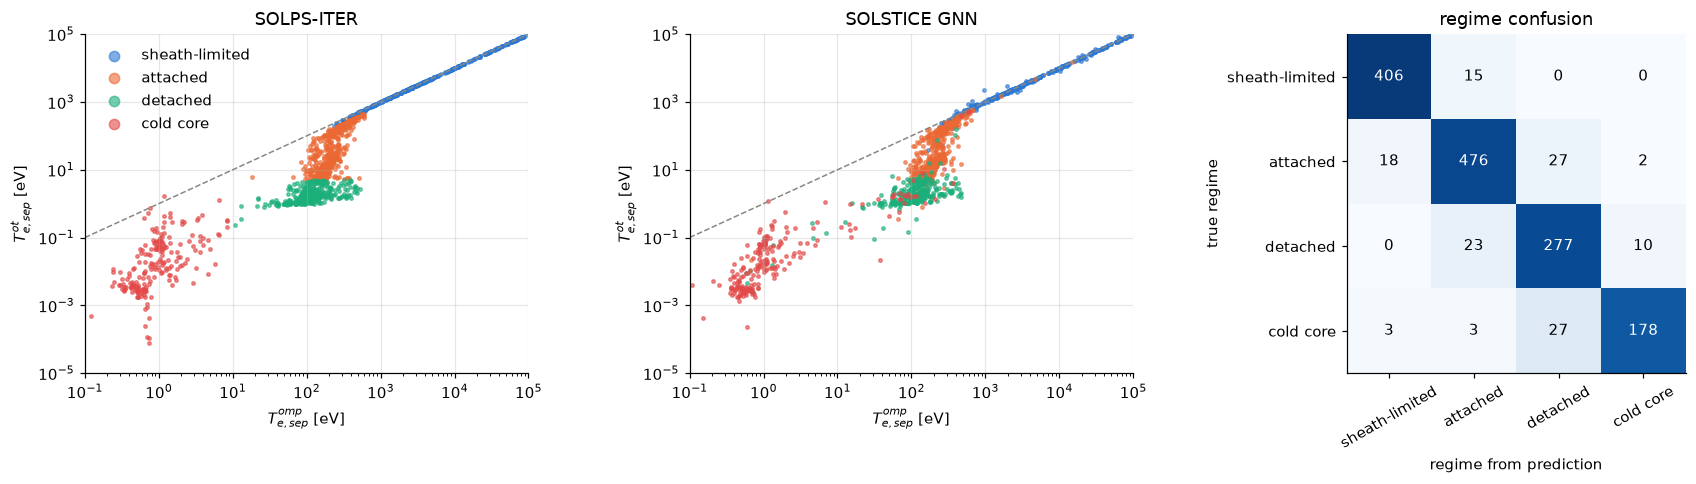

regime recovered from predicted Te in 91.3 % of test cases


In [5]:
te_t, te_p = phys(Yt, 'te'), phys(P, 'te')
def classify(te_omp, te_ot):
    reg = np.full(len(te_omp), 'detached', dtype=object)
    reg[te_ot > 5] = 'attached'; reg[te_ot / te_omp >= 0.8] = 'sheath-limited'; reg[te_omp < 10] = 'cold core'
    return reg.astype(str)
reg_pred = classify(te_p[:, OMP_SEP], te_p[:, OT_SEP])
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, te, lab in ((axs[0], te_t, 'SOLPS-ITER'), (axs[1], te_p, 'SOLSTICE GNN')):
    for r in REGIMES:
        m = regime == r
        ax.scatter(te[m, OMP_SEP], te[m, OT_SEP], s=5, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
    ax.plot([1e-1, 1e5], [1e-1, 1e5], color='#898781', lw=1, ls='--')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(1e-1, 1e5); ax.set_ylim(1e-5, 1e5)
    ax.set_xlabel('$T_{e,sep}^{omp}$ [eV]'); ax.set_ylabel('$T_{e,sep}^{ot}$ [eV]'); ax.set_title(lab)
axs[0].legend(markerscale=3, loc='upper left')
cm = np.array([[np.sum((regime == a) & (reg_pred == b)) for b in REGIMES] for a in REGIMES])
im = axs[2].imshow(cm / cm.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
axs[2].set_xticks(range(4), REGIMES, rotation=30); axs[2].set_yticks(range(4), REGIMES); axs[2].grid(False)
axs[2].set_xlabel('regime from prediction'); axs[2].set_ylabel('true regime'); axs[2].set_title('regime confusion')
for a in range(4):
    for b in range(4):
        axs[2].text(b, a, cm[a, b], ha='center', va='center', color='k' if cm[a, b] < 0.6 * cm[a].sum() else 'w')
plt.tight_layout(); plt.show()
print(f'regime recovered from predicted Te in {100 * (reg_pred == regime).mean():.1f} % of test cases')

## Table 2: electron temperature errors

Median absolute (eV) and relative errors over all 2D cells, at the outer target (all and per regime),
and at the OMP separatrix. Paper values are the NN2D row of Table 2 (their best 2D model).

In [6]:
def med(p, t):
    e = np.abs(p - t)
    with np.errstate(divide='ignore', invalid='ignore'):
        rel = e / np.abs(t)
    return np.median(e), np.median(rel[np.isfinite(rel)])
PAPER_T2 = {'2D all': (3.3, 0.065), 'OT all': (0.97, 0.12), 'OT sheath-limited': (87, 0.082),
            'OT attached': (0.86, 0.11), 'OT detached': (0.18, 0.12), 'OT cold core': (0.012, 0.68),
            'OMP sep': (7.1, 0.043)}
ours = {'2D all': med(te_p, te_t), 'OT all': med(te_p[:, OUTER], te_t[:, OUTER])}
for r in REGIMES:
    m = regime == r
    ours[f'OT {r}'] = med(te_p[m][:, OUTER], te_t[m][:, OUTER])
ours['OMP sep'] = med(te_p[:, OMP_SEP], te_t[:, OMP_SEP])
print(f"{'Te':20s} {'ours abs [eV]':>14s} {'ours rel':>9s} {'NN2D abs':>10s} {'NN2D rel':>9s}")
for k, (pa, pr) in PAPER_T2.items():
    a, r = ours[k]
    print(f'{k:20s} {a:14.3g} {100 * r:8.1f}% {pa:10.3g} {100 * pr:8.1f}%')

Te                    ours abs [eV]  ours rel   NN2D abs  NN2D rel
2D all                         2.38      4.2%        3.3      6.5%
OT all                        0.763      8.9%       0.97     12.0%
OT sheath-limited              54.4      5.2%         87      8.2%
OT attached                   0.657      8.4%       0.86     11.0%
OT detached                   0.137      8.9%       0.18     12.0%
OT cold core                0.00859     55.0%      0.012     68.0%
OMP sep                        4.67      2.5%        7.1      4.3%


## Table 3: outer-target separatrix quantities

`Te`, `ne`, `n_D0`, `n_N0` and `pe = ne Te` at the first SOL cell of the outer target. Paper values are
the NN2D-separated row (one network per observable).

OT separatrix    ours abs  ours rel   NN2D abs  NN2D rel
Te [eV]              2.34     10.4%        2.7     14.0%
ne [m^-3]        5.48e+18     14.2%    1.2e+19     23.0%
nD [m^-3]        6.35e+17     12.2%    9.5e+17     18.0%
nN [m^-3]        3.98e+15     23.7%    4.8e+15     27.0%
pe [Pa]              21.2      9.1%         50     20.0%


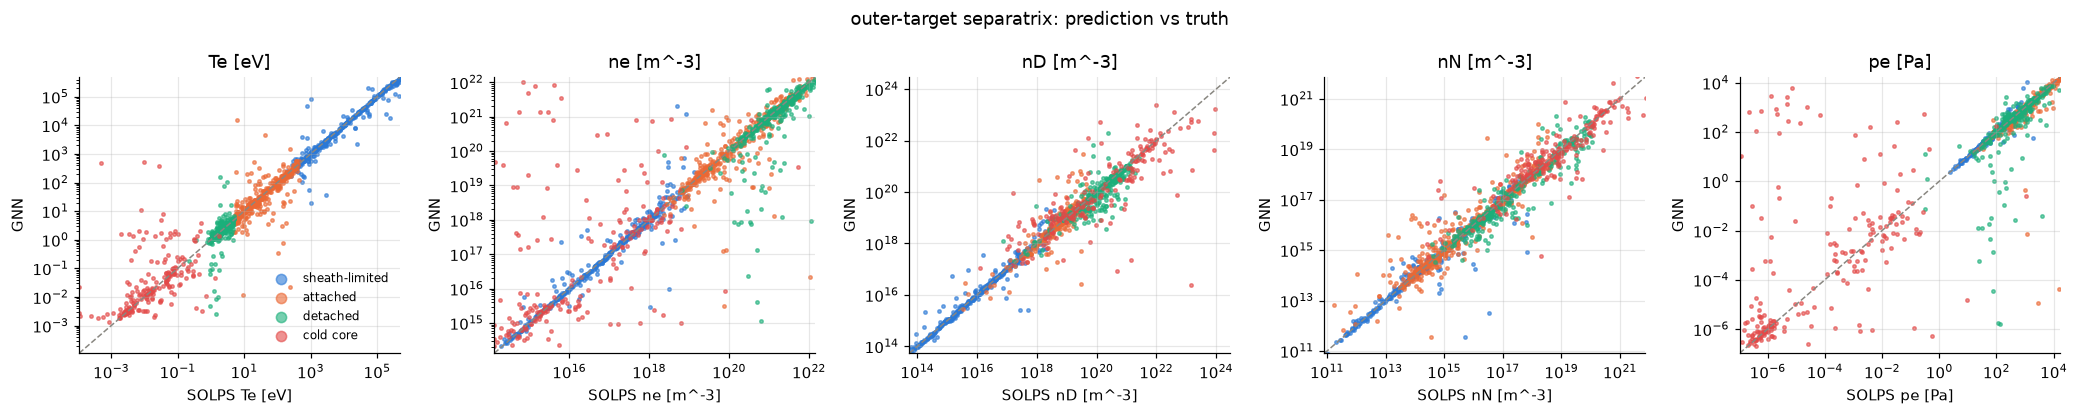

In [7]:
EV = 1.602176634e-19
ne_t, ne_p = phys(Yt, 'ne'), phys(P, 'ne')
q = {'Te [eV]': (te_p[:, OT_SEP], te_t[:, OT_SEP], (2.7, 0.14)),
     'ne [m^-3]': (ne_p[:, OT_SEP], ne_t[:, OT_SEP], (1.2e19, 0.23)),
     'nD [m^-3]': (phys(P, 'na_D0')[:, OT_SEP], phys(Yt, 'na_D0')[:, OT_SEP], (9.5e17, 0.18)),
     'nN [m^-3]': (phys(P, 'na_N0')[:, OT_SEP], phys(Yt, 'na_N0')[:, OT_SEP], (4.8e15, 0.27)),
     'pe [Pa]': (ne_p[:, OT_SEP] * te_p[:, OT_SEP] * EV, ne_t[:, OT_SEP] * te_t[:, OT_SEP] * EV, (50, 0.20))}
print(f"{'OT separatrix':14s} {'ours abs':>10s} {'ours rel':>9s} {'NN2D abs':>10s} {'NN2D rel':>9s}")
for k, (p, t, (pa, pr)) in q.items():
    a, r = med(p, t)
    print(f'{k:14s} {a:10.3g} {100 * r:8.1f}% {pa:10.3g} {100 * pr:8.1f}%')

fig, axs = plt.subplots(1, 5, figsize=(19, 3.8))
for ax, (k, (p, t, _)) in zip(axs, q.items()):
    for r in REGIMES:
        m = regime == r
        ax.scatter(t[m], p[m], s=5, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
    lo, hi = np.nanpercentile(t[t > 0], [0.5, 99.5])
    ax.plot([lo, hi], [lo, hi], color='#898781', lw=1, ls='--'); ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_xlabel(f'SOLPS {k}'); ax.set_ylabel('GNN'); ax.set_title(k)
axs[0].legend(markerscale=3, fontsize=8); fig.suptitle('outer-target separatrix: prediction vs truth'); plt.tight_layout(); plt.show()

## Figure 2: 2D fields for one attached test case

`Te`, `ne`, `n_D0`, `n_N0`: SOLPS truth, prediction, and the relative error, on the R-scaled grid with a
divertor zoom. The case is picked as in the paper (attached, `Te_omp` between 100 and 300 eV).

test case test_00337: attached, R = 8.77 m, Te_omp 135 eV, Te_ot 11.2 eV


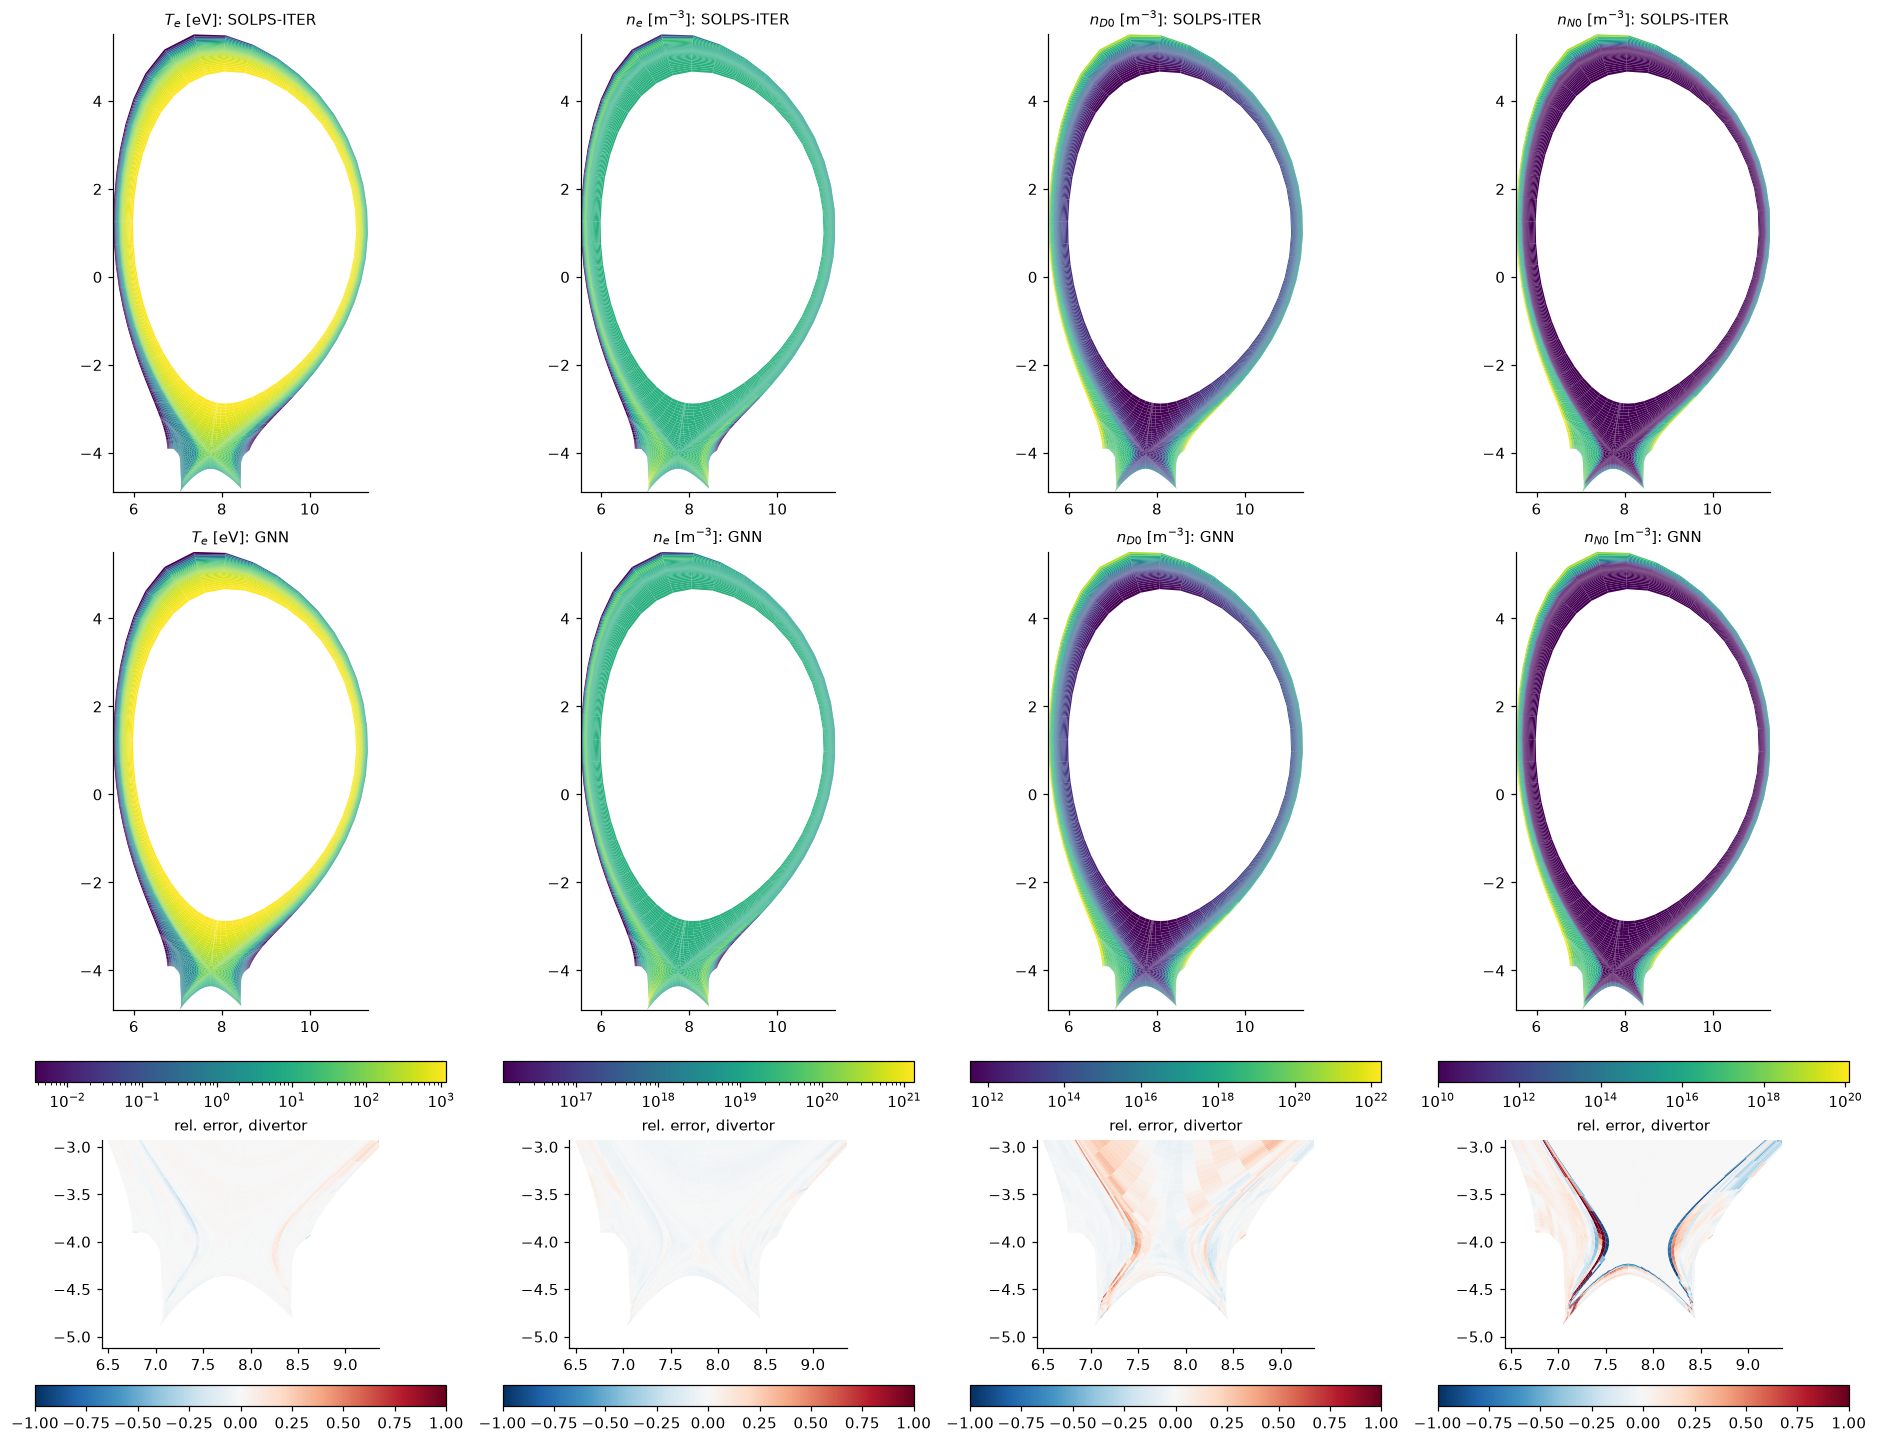

In [8]:
cand = np.where((regime == 'attached') & (te_t[:, OMP_SEP] > 100) & (te_t[:, OMP_SEP] < 300))[0]
k = int(cand[len(cand) // 2]) if len(cand) else 0
s_k = float(dt['mesh_scale'].values[idx[k]])
print(f'test case {dt.case.values[idx[k]]}: {regime[k]}, R = {s_k * dt.attrs["mesh_reference_rmajor"]:.2f} m, '
      f'Te_omp {te_t[k, OMP_SEP]:.0f} eV, Te_ot {te_t[k, OT_SEP]:.1f} eV')
ZOOM = (2.2, 3.2, -1.75, -1.0)
show = [('$T_e$ [eV]', 'te'), ('$n_e$ [m$^{-3}$]', 'ne'), ('$n_{D0}$ [m$^{-3}$]', 'na_D0'), ('$n_{N0}$ [m$^{-3}$]', 'na_N0')]
fig, axs = plt.subplots(3, 4, figsize=(17, 13), gridspec_kw={'height_ratios': [2.2, 2.2, 1]}, constrained_layout=True)
for j, (lab, name) in enumerate(show):
    t, p = phys(Yt, name)[k], phys(P, name)[k]
    vmin, vmax = np.nanpercentile(t[t > 0], [1, 99.9])
    plot_field(axs[0, j], t, s_k, vmin=vmin, vmax=vmax, title=f'{lab}: SOLPS-ITER')
    pc = plot_field(axs[1, j], p, s_k, vmin=vmin, vmax=vmax, title=f'{lab}: GNN')
    fig.colorbar(pc, ax=axs[1, j], location='bottom', shrink=0.9, pad=0.05)
    err = (p - t) / np.abs(t)
    pe_ = plot_field(axs[2, j], err, s_k, log=False, vmin=-1, vmax=1, cmap='RdBu_r', zoom=ZOOM, title='rel. error, divertor')
    fig.colorbar(pe_, ax=axs[2, j], location='bottom', shrink=0.9, pad=0.05)
plt.show()

## Figure 3: outer-target `Te` profiles for eight test cases

Two sheath-limited, three attached, two detached, one cold-core case (seeded pick), truth vs prediction
against distance along the target. The paper notes the private-flux-edge spike in cold cases.

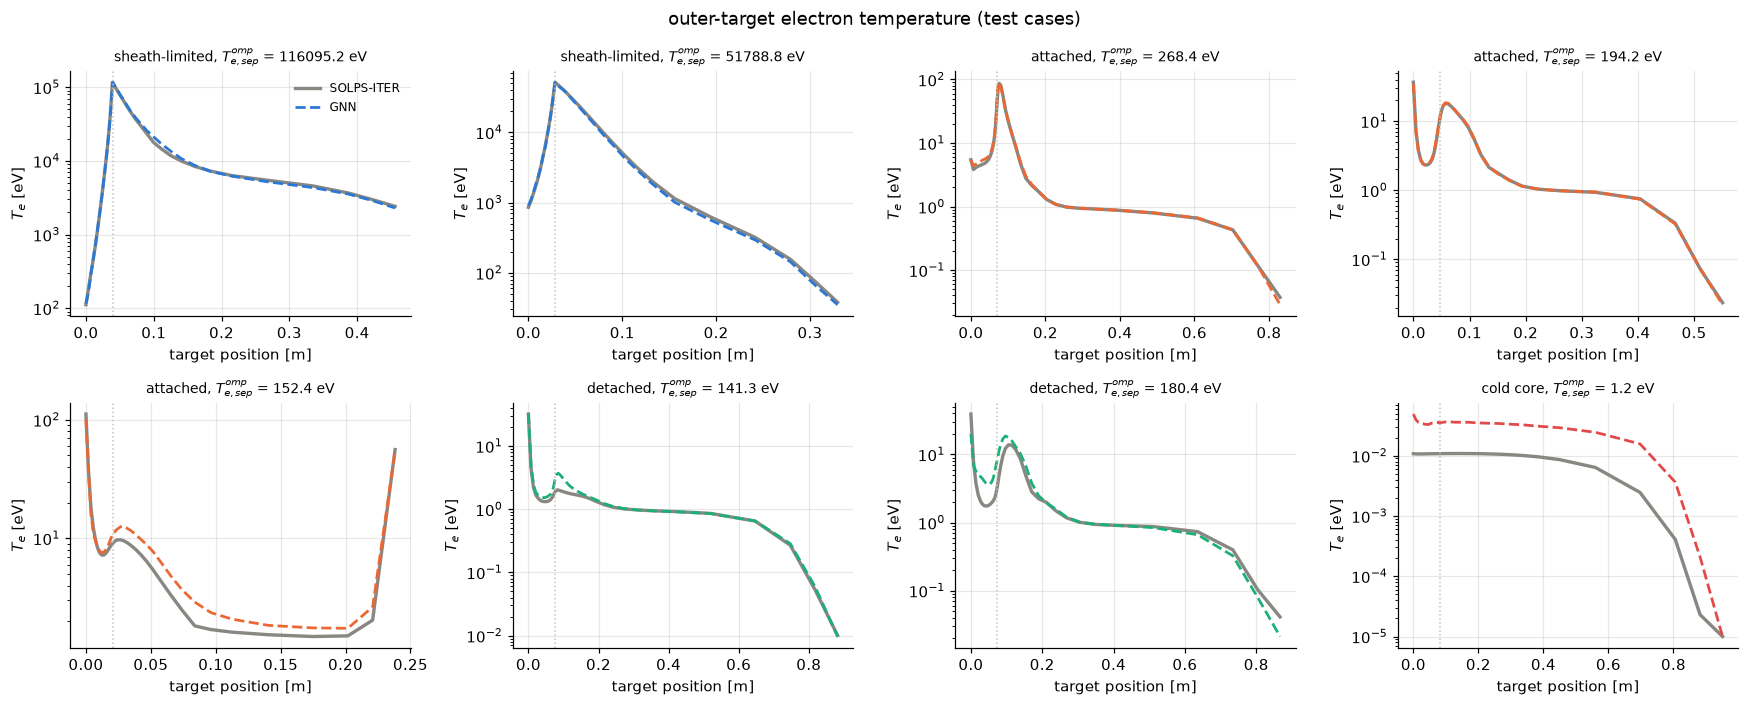

In [9]:
rng = np.random.default_rng(0)
picks = []
for r, n in (('sheath-limited', 2), ('attached', 3), ('detached', 2), ('cold core', 1)):
    ii = np.where(regime == r)[0]
    picks += list(rng.choice(ii, size=min(n, len(ii)), replace=False))
fig, axs = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, kp in zip(axs.ravel(), picks):          # kp: keep k = the Figure 2 case for the maps below
    s = target_position(kp)
    ax.plot(s, te_t[kp, OUTER], color='#898781', lw=2.2, label='SOLPS-ITER')
    ax.plot(s, te_p[kp, OUTER], color=RCOL[regime[kp]], lw=1.8, ls='--', label='GNN')
    ax.axvline(s[IY_SEP - 1], color='#c3c2b7', lw=1, ls=':')
    ax.set_yscale('log'); ax.set_xlabel('target position [m]'); ax.set_ylabel('$T_e$ [eV]')
    ax.set_title(f'{regime[kp]}, $T_{{e,sep}}^{{omp}}$ = {te_t[kp, OMP_SEP]:.1f} eV', fontsize=9)
axs[0, 0].legend(fontsize=8); fig.suptitle('outer-target electron temperature (test cases)'); plt.tight_layout(); plt.show()

## Table 4 / Figure 5: peak outer-target heat flux

The store carries the release's own `pwmxap`. Ours comes from the auxiliary target head (`q_target`,
face-centred, the same quantity) and, for comparison, from the cell-centred `q_pol` field. Paper rows:
the direct scalar network and NN2D+SOLPS (state variables written to b2fstati, no iteration).

q_peak,ot rel. error                         all  sheath-limited        attached        detached       cold core
q_target head                               8.2%            3.4%            5.3%           17.6%           92.6%
q_pol field (cell-centred)                  9.2%            4.6%            6.8%           25.9%           81.5%
paper Direct                               13.0%            5.5%            9.2%           34.0%           98.0%
paper NN2D+SOLPS                          170.0%          310.0%           43.0%           41.0%        15000.0%
paper NN2D+SOLPS+1000 steps                12.0%            4.6%            7.4%           23.0%           99.0%

Gamma_D+,ot rel. error                       all  sheath-limited        attached        detached       cold core
gamma_target head, integrated               7.6%            4.9%            4.7%            8.6%           99.9%
paper Direct                               15.0%           15.0%            8.5%           15.0

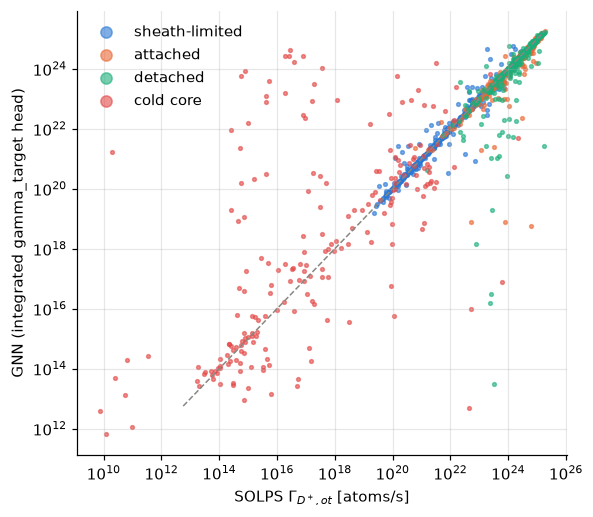

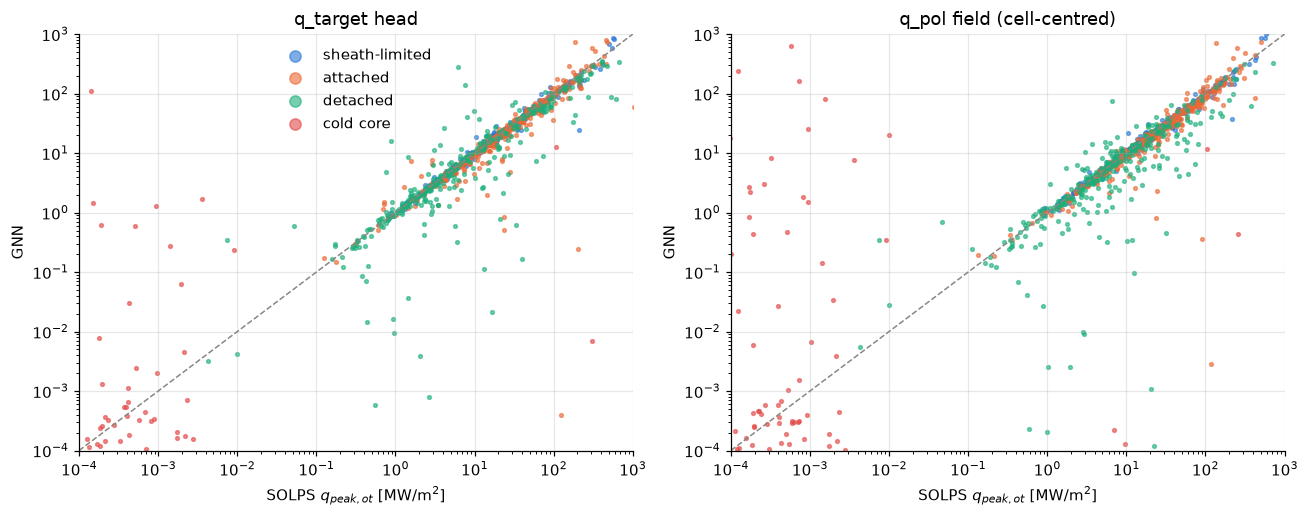

In [10]:
pw_t = dt['pwmxap'].values[idx]
srcs = {}
if 'q_target' in J:
    srcs['q_target head'] = np.abs(phys(P, 'q_target')[:, OUTER]).max(1)
if 'q_pol' in J:
    srcs['q_pol field (cell-centred)'] = np.abs(phys(P, 'q_pol')[:, OUTER]).max(1)
    qt_cc = np.abs(phys(Yt, 'q_pol')[:, OUTER]).max(1)
PAPER_T4 = {'Direct': (0.13, 0.055, 0.092, 0.34, 0.98), 'NN2D+SOLPS': (1.7, 3.1, 0.43, 0.41, 150),
            'NN2D+SOLPS+1000 steps': (0.12, 0.046, 0.074, 0.23, 0.99)}
cols = ['all'] + REGIMES
print(f"{'q_peak,ot rel. error':32s}" + ''.join(f'{c:>16s}' for c in cols))
for lab, pk in srcs.items():
    ref = pw_t if lab.startswith('q_target') else qt_cc
    rel = np.abs(pk - ref) / ref
    vals = [np.median(rel)] + [np.median(rel[regime == r]) for r in REGIMES]
    print(f'{lab:32s}' + ''.join(f'{100 * v:15.1f}%' for v in vals))
for lab, vals in PAPER_T4.items():
    print(f'{"paper " + lab:32s}' + ''.join(f'{100 * v:15.1f}%' for v in vals))

if 'gamma_target' in J:
    # integrated D+ flux to the outer target from the gamma_target head vs the release's fnixap
    area = dt['outer_target_area'].values[None] * dt['mesh_scale'].values[idx][:, None] ** 2
    G_p = (phys(P, 'gamma_target')[:, OUTER] * area).sum(1)
    G_t = dt['fnixap'].values[idx]
    rel = np.abs(G_p - G_t) / np.abs(G_t)
    vals = [np.median(rel)] + [np.median(rel[regime == r]) for r in REGIMES]
    print()
    print(f"{'Gamma_D+,ot rel. error':32s}" + ''.join(f'{c:>16s}' for c in cols))
    print(f'{"gamma_target head, integrated":32s}' + ''.join(f'{100 * v:15.1f}%' for v in vals))
    for lab, v in {'Direct': (0.15, 0.15, 0.085, 0.15, 6.7), 'NN2D+SOLPS': (0.15, 0.13, 0.089, 0.16, 1.0)}.items():
        print(f'{"paper " + lab:32s}' + ''.join(f'{100 * x:15.1f}%' for x in v))
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    for r in REGIMES:
        m = regime == r
        ax.scatter(np.abs(G_t[m]), np.abs(G_p[m]), s=6, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
    lo, hi = np.nanpercentile(np.abs(G_t), [0.5, 99.9])
    ax.plot([lo, hi], [lo, hi], color='#898781', lw=1, ls='--'); ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('SOLPS $\\Gamma_{D^+,ot}$ [atoms/s]'); ax.set_ylabel('GNN (integrated gamma_target head)'); ax.legend(markerscale=3)
    plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, len(srcs), figsize=(6 * len(srcs), 4.8), squeeze=False)
for ax, (lab, pk) in zip(axs[0], srcs.items()):
    ref = pw_t if lab.startswith('q_target') else qt_cc
    for r in REGIMES:
        m = regime == r
        ax.scatter(ref[m] / 1e6, pk[m] / 1e6, s=6, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
    ax.plot([1e-4, 1e3], [1e-4, 1e3], color='#898781', lw=1, ls='--'); ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-4, 1e3); ax.set_ylim(1e-4, 1e3); ax.set_xlabel('SOLPS $q_{peak,ot}$ [MW/m$^2$]'); ax.set_ylabel('GNN'); ax.set_title(lab)
axs[0, 0].legend(markerscale=3); plt.tight_layout(); plt.show()

## Beyond the paper: radiated power and poloidal heat flux fields

SOLPS-NN does not predict these; the release ships them and the GNN learns them jointly. Same
attached test case as Figure 2.

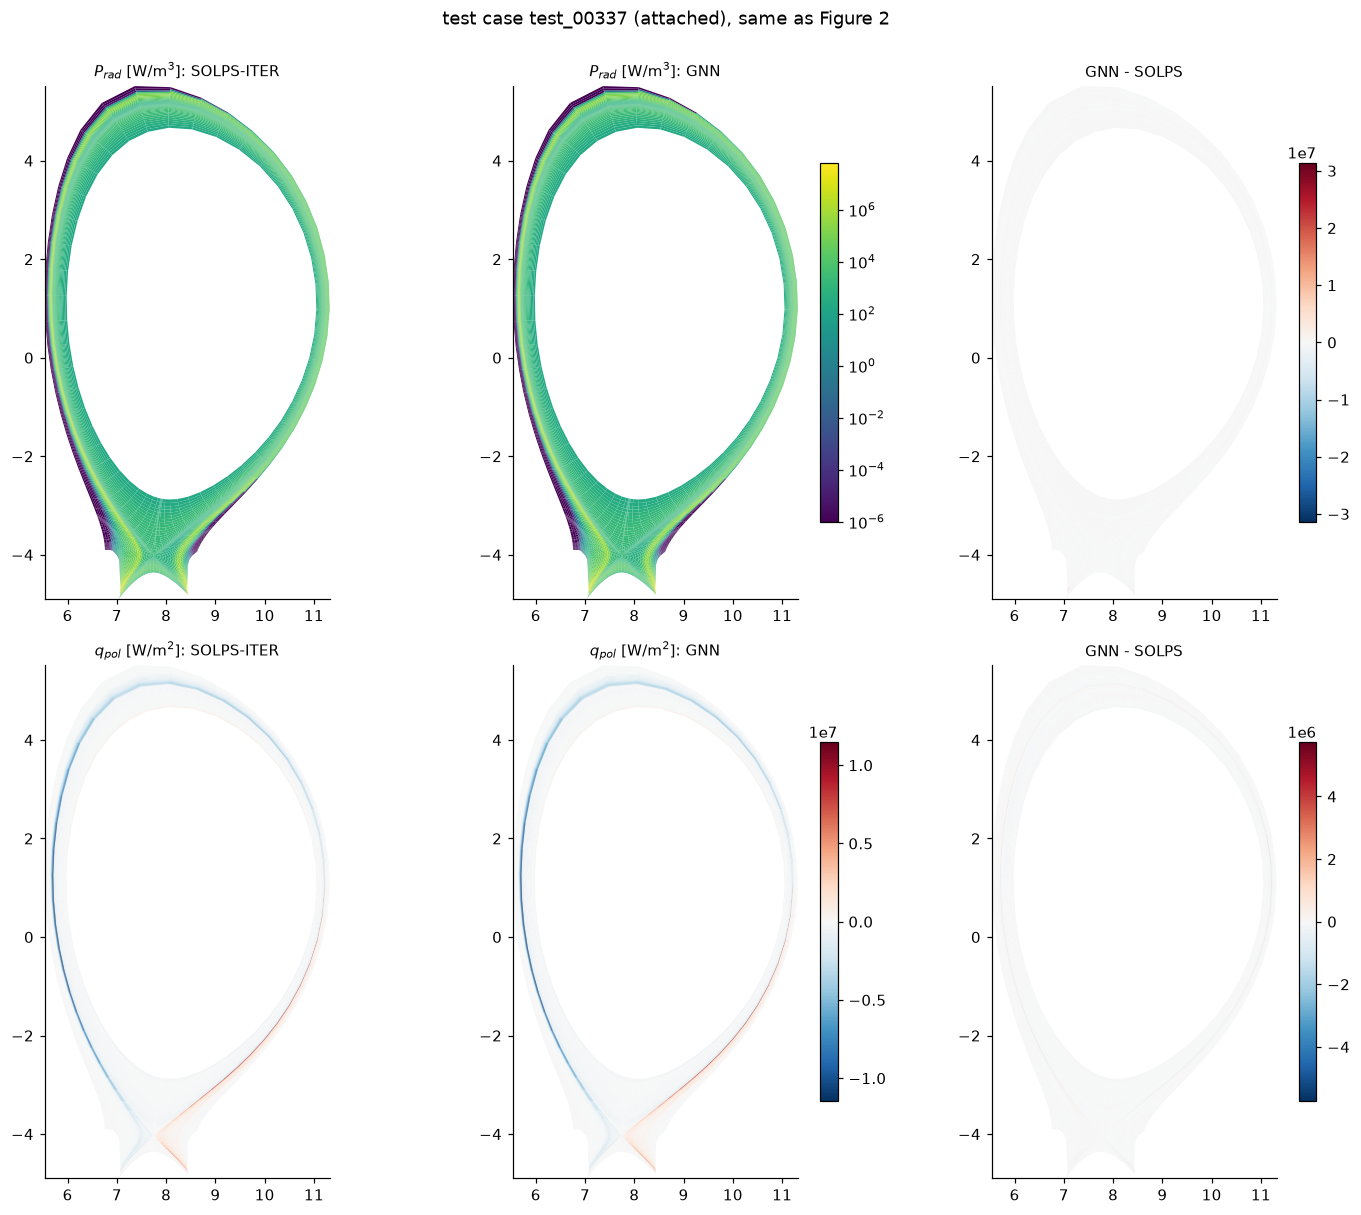

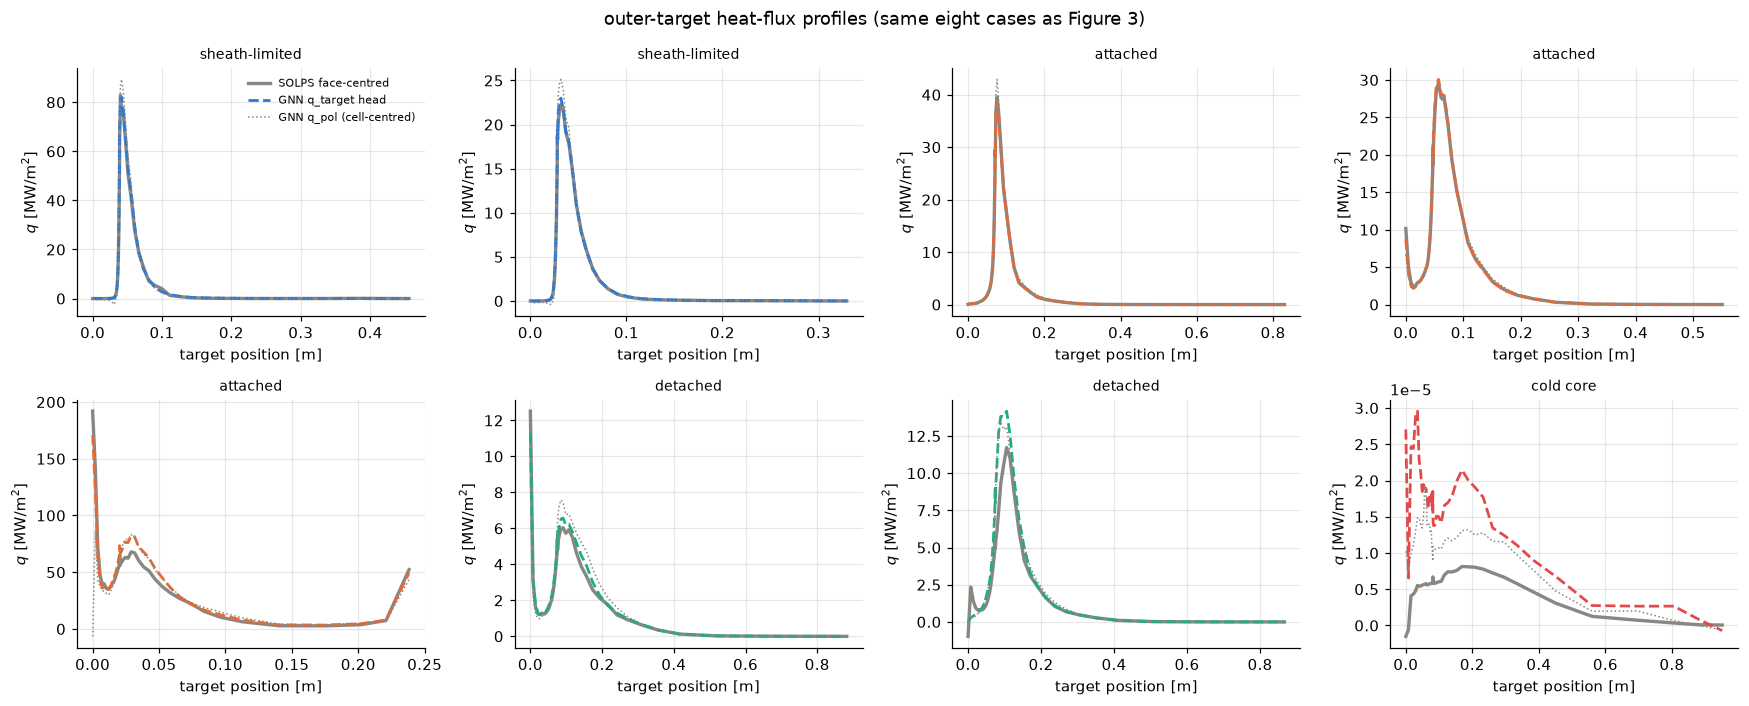

In [11]:
extra = [(n, lab, log) for n, lab, log in [('prad', '$P_{rad}$ [W/m$^3$]', True), ('q_pol', '$q_{pol}$ [W/m$^2$]', False)] if n in J]
fig, axs = plt.subplots(len(extra), 3, figsize=(13, 5.5 * len(extra)), squeeze=False)
for row, (name, lab, log) in zip(axs, extra):
    t, p = phys(Yt, name)[k], phys(P, name)[k]
    if log:
        vmin, vmax = np.nanpercentile(t[t > 0], [1, 99.9]); kw = dict(vmin=vmin, vmax=vmax)
    else:
        v = np.nanpercentile(np.abs(t), 99); kw = dict(vmin=-v, vmax=v, cmap='RdBu_r')
    plot_field(row[0], t, s_k, log=log, title=f'{lab}: SOLPS-ITER', **kw)
    pc = plot_field(row[1], p, s_k, log=log, title=f'{lab}: GNN', **kw)
    fig.colorbar(pc, ax=row[1], shrink=0.7)
    d = plot_field(row[2], p - t, s_k, log=False, vmin=-kw['vmax'] * 0.5, vmax=kw['vmax'] * 0.5, cmap='RdBu_r', title='GNN - SOLPS')
    fig.colorbar(d, ax=row[2], shrink=0.7)
fig.suptitle(f'test case {dt.case.values[idx[k]]} ({regime[k]}), same as Figure 2', y=1.0); plt.tight_layout(); plt.show()
if 'q_target' in J and 'q_pol' in J:
    fig, axs = plt.subplots(2, 4, figsize=(16, 6.5))
    for ax, kk in zip(axs.ravel(), picks):
        s = target_position(kk)
        ax.plot(s, phys(Yt, 'q_target')[kk, OUTER] / 1e6, color='#898781', lw=2.2, label='SOLPS face-centred')
        ax.plot(s, phys(P, 'q_target')[kk, OUTER] / 1e6, color=RCOL[regime[kk]], lw=1.8, ls='--', label='GNN q_target head')
        ax.plot(s, phys(P, 'q_pol')[kk, OUTER] / 1e6, color='#898781', lw=1, ls=':', label='GNN q_pol (cell-centred)')
        ax.set_xlabel('target position [m]'); ax.set_ylabel('$q$ [MW/m$^2$]'); ax.set_title(regime[kk], fontsize=9)
    axs[0, 0].legend(fontsize=7); fig.suptitle('outer-target heat-flux profiles (same eight cases as Figure 3)'); plt.tight_layout(); plt.show()

## Deep-ensemble uncertainty: does the seed spread track the error?

For every test cell, the standard deviation of `Te` across the ensemble members (`te_std`) against
the absolute error of the ensemble mean. A calibrated ensemble has errors growing with the spread,
and about two thirds of the errors below one standard deviation. Right: the per-case spread at the
OMP and outer-target separatrix, coloured by regime.

cells with |error| < 1 std: 59% (Gaussian 68%), < 2 std: 84% (95%); median std / median |error| = 1.28


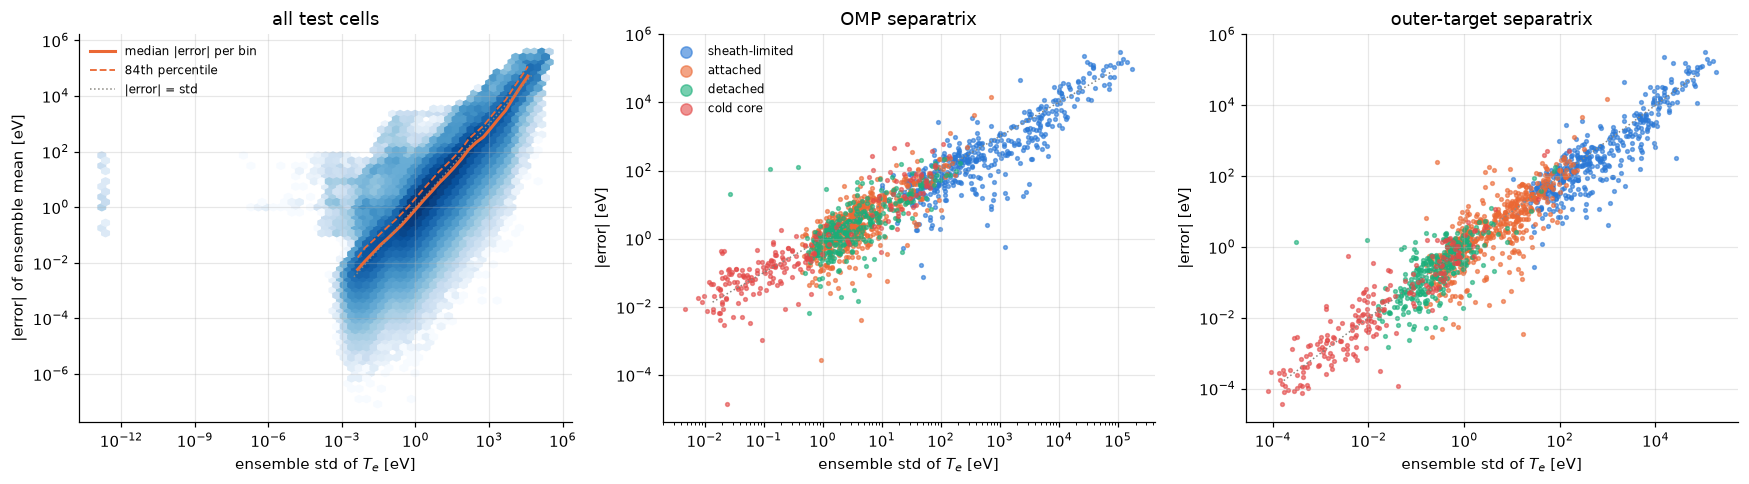

In [12]:
if len(RUNS) > 1:
    err = np.abs(te_mean - te_t); sd = te_std
    ok = (te_t > 0.1) & np.isfinite(err) & (sd > 0)
    e, s = err[ok], sd[ok]
    bins = np.logspace(np.log10(np.percentile(s, 0.5)), np.log10(np.percentile(s, 99.5)), 25)
    which = np.digitize(s, bins)
    cen, q50, q84 = [], [], []
    for b in range(1, len(bins)):
        mb = which == b
        if mb.sum() < 50:
            continue
        cen.append(np.sqrt(bins[b - 1] * bins[b])); q50.append(np.median(e[mb])); q84.append(np.percentile(e[mb], 84))
    frac = np.mean(e < s); frac2 = np.mean(e < 2 * s)
    print(f'cells with |error| < 1 std: {100 * frac:.0f}% (Gaussian 68%), < 2 std: {100 * frac2:.0f}% (95%); '
          f'median std / median |error| = {np.median(s) / np.median(e):.2f}')
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
    ax = axs[0]
    ax.hexbin(s, e, xscale='log', yscale='log', gridsize=60, bins='log', cmap='Blues', mincnt=1, rasterized=True)
    ax.plot(cen, q50, color='#eb6834', lw=2, label='median |error| per bin'); ax.plot(cen, q84, color='#eb6834', lw=1.2, ls='--', label='84th percentile')
    ax.plot([bins[0], bins[-1]], [bins[0], bins[-1]], color='#898781', lw=1, ls=':', label='|error| = std')
    ax.set_xlabel('ensemble std of $T_e$ [eV]'); ax.set_ylabel('|error| of ensemble mean [eV]'); ax.set_title('all test cells'); ax.legend(fontsize=8)
    for ax, cell, lab in ((axs[1], OMP_SEP, 'OMP separatrix'), (axs[2], OT_SEP, 'outer-target separatrix')):
        for r in REGIMES:
            m = regime == r
            ax.scatter(te_std[m, cell], np.abs(te_mean - te_t)[m, cell], s=6, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
        lo, hi = np.nanpercentile(te_std[:, cell][te_std[:, cell] > 0], [0.5, 99.5])
        ax.plot([lo, hi], [lo, hi], color='#898781', lw=1, ls=':'); ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_xlabel('ensemble std of $T_e$ [eV]'); ax.set_ylabel('|error| [eV]'); ax.set_title(lab)
    axs[1].legend(markerscale=3, fontsize=8); plt.tight_layout(); plt.show()
else:
    print('single run: no ensemble spread')

## Full metric table (what `metrics.json` holds)

In [13]:
res = evaluate(dt, idx, out_norm, P, Yt)
print(format_metrics(res))

field          R2  RMSEn  all: med abs    rel  OT: med abs    rel  OMPsep: abs    rel
te          0.914  0.303           2.4   4.2%        0.774   9.0%         4.53   2.4%
ti          0.898  0.330          4.95   4.9%        0.959   9.5%         9.62   3.1%
ne          0.916  0.290      8.37e+17   7.6%     2.09e+18  15.5%     6.05e+17   4.2%
na_D0       0.881  0.344      2.15e+14  11.1%     1.42e+18  13.6%     3.34e+13   7.1%
na_D1       0.904  0.313      6.22e+17   8.4%      1.4e+18  16.9%     4.98e+17   5.0%
na_N0       0.898  0.285      3.21e+12   9.9%     5.73e+15  23.8%     2.52e+11   4.3%
na_N1       0.876  0.341      6.26e+12  13.5%     2.92e+15  27.2%     1.06e+12   5.5%
na_N2       0.819  0.420      2.81e+12  13.9%     4.77e+14  28.3%     2.27e+12   6.1%
na_N3       0.869  0.361      1.61e+13  17.7%     3.87e+14  31.3%     4.09e+12   8.7%
na_N4       0.828  0.420      1.89e+13  14.3%     3.58e+13  25.1%     1.62e+13   8.9%
na_N5       0.823  0.426      2.39e+14  12.5%     8.99